In [ ]:
5.3: Inverse Filtering

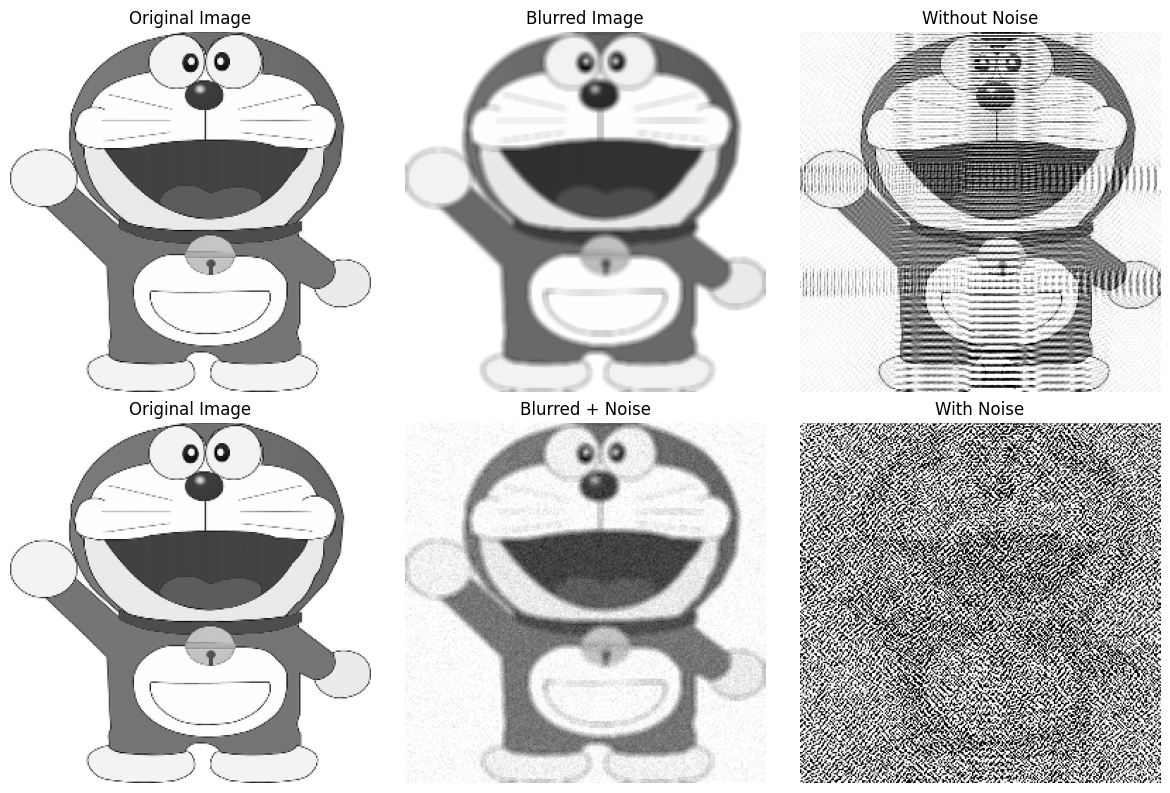

Assignment 5.3 Completed Successfully!


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load Original Image
img = cv2.imread('/content/image.png', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Please upload image.png")

img = cv2.resize(img, (256, 256))

# Step 2: Create Degradation Function (Blur)
kernel = np.ones((5, 5), np.float32) / 25

# Apply Blur
blurred = cv2.filter2D(img, -1, kernel)

# Step 3: Create Noisy Image
noise = np.random.normal(0, 10, blurred.shape)

blurred_noisy = np.clip(
    blurred.astype(float) + noise, 0, 255
).astype(np.uint8)

# Step 4: Convert Kernel to Frequency Domain
psf = np.zeros(img.shape, dtype=np.float32)
kh, kw = kernel.shape

psf[:kh, :kw] = kernel
psf = np.roll(psf, -kh // 2, axis=0)
psf = np.roll(psf, -kw // 2, axis=1)

H = np.fft.fft2(psf)

# Step 5: Inverse Filtering Function
def inverse_filter(degraded, H):
    G = np.fft.fft2(degraded)

    epsilon = 0.01
    F = G / (H + epsilon)

    restored = np.fft.ifft2(F)
    restored = np.real(restored)

    return np.clip(restored, 0, 255).astype(np.uint8)

# Step 6: Without Noise
restored_without_noise = inverse_filter(blurred, H)

# Step 7: With Noise
restored_with_noise = inverse_filter(blurred_noisy, H)

# Step 8: Display Results
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(blurred, cmap='gray')
plt.title("Blurred Image")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(restored_without_noise, cmap='gray')
plt.title("Without Noise")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(blurred_noisy, cmap='gray')
plt.title("Blurred + Noise")
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(restored_with_noise, cmap='gray')
plt.title("With Noise")
plt.axis('off')

plt.tight_layout()
plt.show()

# Step 9: Save Results
cv2.imwrite('/content/5_3_Without_Noise.png',
            restored_without_noise)

cv2.imwrite('/content/5_3_With_Noise.png',
            restored_with_noise)

print("Assignment 5.3 Completed Successfully!")